IMPORTS

In [3]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

LOAD DATASET

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

PREPARING DATASET

In [5]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  str    
 2   fuel_type            10000 non-null  str    
 3   drivetrain           10000 non-null  str    
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 859.5 KB


In [7]:
df['horsepower'] = df['horsepower'].fillna(0)
df['acceleration'] = df['acceleration'].fillna(0)


In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [9]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [10]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values


In [11]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [12]:
train_dict = df_train.to_dict(orient='records')
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

QUESTION 1

In [13]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.tree import export_text

dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



QUESTION 2

In [14]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [15]:
y_pred_rf = rf.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_rf))
print(rmse)

1.833219735874562


QUESTION 3

In [16]:
n_values = [10, 50, 100, 150]

for n in n_values:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred_rf = rf.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_rf))

    print(f'RMSE {n}: {rmse:.3f}')

RMSE 10: 1.833
RMSE 50: 1.774
RMSE 100: 1.770
RMSE 150: 1.769


QUESTION 4

In [17]:
max_depths = [10, 15, 20, 25]
n_values = [10, 50, 100, 150]
scores = []

for max_depth in max_depths:
    for n in n_values:
        rf = RandomForestRegressor(n_estimators=n, max_depth=max_depth, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
    
        y_pred_rf = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred_rf))
    
        scores.append((max_depth, n, rmse))
columns = ['max_depth', 'n_estimator', 'rmse']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores = df_scores.pivot(columns='max_depth', values='rmse', index='n_estimator')
df_scores

max_depth,10,15,20,25
n_estimator,,,,
10,1.782348,1.831390,1.837314,1.836852
50,1.747520,1.770883,1.772377,1.772123
100,1.743986,1.767872,1.768918,1.768320
150,1.743716,1.766752,1.768476,1.767927


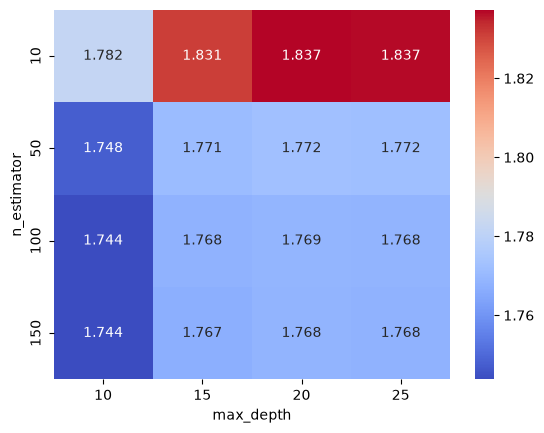

In [18]:
sns.heatmap(df_scores, annot=True, fmt=".3f", cmap="coolwarm")
plt.show()

QUESTION 5

In [19]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_l

In [20]:
feature_names = dv.get_feature_names_out()
importance = rf.feature_importances_

In [21]:
rf.feature_importances_

array([0.05499763, 0.00795063, 0.02006223, 0.00563848, 0.06128144,
       0.01657053, 0.16071245, 0.01627193, 0.07827125, 0.29610715,
       0.00731824, 0.01940147, 0.00651495, 0.00343644, 0.04215174,
       0.20331344])

In [22]:
pd.DataFrame({
    'feature': dv.get_feature_names_out(),
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

,feature,importance
9,model_year,0.296107
15,vehicle_weight,0.203313
6,fuel_type=Gasoline,0.160712
8,horsepower,0.078271
4,engine_displacement,0.061281
0,acceleration,0.054998
14,origin=USA,0.042152
2,drivetrain=Front-wheel drive,0.020062
11,num_doors,0.019401
5,fuel_type=Diesel,0.016571


QUESTION 6

In [23]:
import xgboost as xgb

In [24]:
feature_names = list(feature_names)

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

In [25]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [26]:
scores = {}
etas = [0.1, 0.3]

In [27]:
for eta in etas:
    evals_result = {}
    
    xgb_params = {
    'eta': eta, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
    }

    model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=5, evals_result=evals_result)

    columns = ['iter', 'train_rmse', 'val_rmse']
    train_aucs = list(evals_result['train'].values())[0]
    val_aucs = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)),
        columns=columns
    )

    key = f'eta={eta}'
    scores[key] = df_results

[0]	train-rmse:2.74739	val-rmse:2.78635
[5]	train-rmse:2.12109	val-rmse:2.20428
[10]	train-rmse:1.80592	val-rmse:1.93152
[15]	train-rmse:1.64286	val-rmse:1.80346
[20]	train-rmse:1.55847	val-rmse:1.75076
[25]	train-rmse:1.50918	val-rmse:1.72751
[30]	train-rmse:1.47544	val-rmse:1.71667
[35]	train-rmse:1.44978	val-rmse:1.71287
[40]	train-rmse:1.43074	val-rmse:1.71289
[45]	train-rmse:1.41543	val-rmse:1.71310
[50]	train-rmse:1.40368	val-rmse:1.71358
[55]	train-rmse:1.39009	val-rmse:1.71570
[60]	train-rmse:1.37884	val-rmse:1.71688
[65]	train-rmse:1.37172	val-rmse:1.71812
[70]	train-rmse:1.36283	val-rmse:1.71919
[75]	train-rmse:1.35099	val-rmse:1.72057
[80]	train-rmse:1.34578	val-rmse:1.72100
[85]	train-rmse:1.33480	val-rmse:1.72192
[90]	train-rmse:1.32546	val-rmse:1.72303
[95]	train-rmse:1.32292	val-rmse:1.72324
[99]	train-rmse:1.31192	val-rmse:1.72481
[0]	train-rmse:2.40653	val-rmse:2.46782
[5]	train-rmse:1.59328	val-rmse:1.76216
[10]	train-rmse:1.47125	val-rmse:1.73205
[15]	train-rmse:1.41

In [28]:
df_results

,iter,train_rmse,val_rmse
0,1,2.406533,2.467818
1,2,2.070983,2.157844
2,3,1.864543,1.973981
3,4,1.733604,1.866615
4,5,1.650587,1.803121
...,...,...,...
95,96,0.918054,1.825438
96,97,0.916286,1.825539
97,98,0.913604,1.825055
98,99,0.907600,1.825755


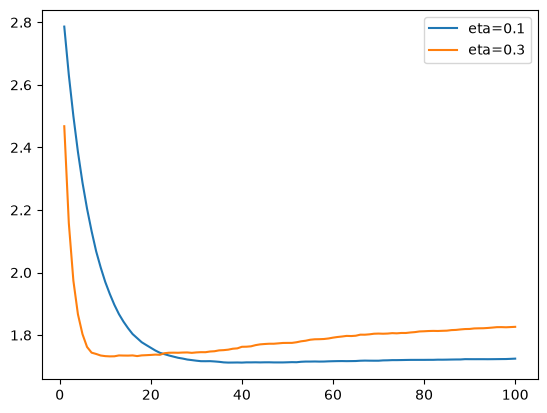

In [29]:
for key, df_results in scores.items():
    plt.plot(df_results.iter, df_results.val_rmse, label=key)
    
plt.legend()
plt.show()

In [30]:
for key, df_results in scores.items():
    print(key, 'Round:', df_results.val_rmse.idxmin() + 1, '|', 'RMSE:', df_results.val_rmse.min())

eta=0.1 Round: 40 | RMSE: 1.7121714763059768
eta=0.3 Round: 11 | RMSE: 1.7320478064805087
